# Module 04 - Multi-Object Tracking and Evaluation (ByteTrack and BoT-SORT)

**Course:** CS 5567 – Deep Learning  **Runtime:** GPU

**Objective.** This notebook links the fine-tuned detector's output across video frames into persistent pedestrian identities, and evaluates the resulting tracks with standard benchmark metrics.

**Procedure**
1. Load the detector weights from Notebook 03.
2. Run ByteTrack and BoT-SORT on the validation sequence (MOT16-09, never used for training).
3. Export the tracks in MOT Challenge format (`frame, id, x, y, w, h, conf`).
4. Evaluate against the ground truth with TrackEval (HOTA, MOTA, IDF1, identity switches), cross-checked with `motmetrics`.
5. Compare configurations: pretrained vs. fine-tuned detector, and ByteTrack vs. BoT-SORT.
6. Examine the sensitivity of the tracker to its main parameters.
7. Render an annotated video and a single-target highlight video.

**Key result.** The comparison table in step 5 shows the contribution of each component in tracking metrics rather than by visual inspection.

In [ ]:
# 1. Setup: Drive, packages, paths
from google.colab import drive
drive.mount('/content/drive')
!pip -q install ultralytics motmetrics lap
from pathlib import Path
import time, shutil, subprocess, sys
import numpy as np, pandas as pd

CANDIDATES = [Path('/content/drive/MyDrive/MOT16_project/Backup'),
              Path('/content/drive/MyDrive/MOT16_project'),
              Path('/content/drive/MyDrive/DL_Video_Tracking ')]      # trailing space is intentional
BASE = next((p for p in CANDIDATES if (p/'yolo_mot16_best.pt').exists()), None)
assert BASE, 'yolo_mot16_best.pt not found - run Notebook 03 (last cell) first'
RESULTS = BASE/'results'; RESULTS.mkdir(exist_ok=True)
print('BASE:', BASE)

BASE: /content/drive/MyDrive/MOT16_project/Backup


In [ ]:
# 2. Configuration (the only cell you normally edit)
import torch
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NONE - set runtime to GPU')

SEQ         = 'MOT16-09'                 # validation sequence; the detector never trained on it
WEIGHTS_FT  = str(BASE/'yolo_mot16_best.pt')
WEIGHTS_PRE = 'yolo26m.pt'               # must match the pretrained model used in Notebook 03
IMGSZ       = 960
DET_CONF    = 0.1                        # low on purpose: ByteTrack needs low-score boxes for its second association pass

# locate MOT16 on Drive and copy only the validation sequence to local disk
MOT_DRIVE = next((p for p in [BASE/'MOT16', BASE.parent/'MOT16', BASE.parent/'Backup'/'MOT16'] if (p/'train'/SEQ).exists()), None)
assert MOT_DRIVE, 'MOT16 folder not found next to the weights'
SEQ_DIR = Path('/content/MOT16')/'train'/SEQ
if not SEQ_DIR.exists():
    SEQ_DIR.parent.mkdir(parents=True, exist_ok=True)
    shutil.copytree(MOT_DRIVE/'train'/SEQ, SEQ_DIR)
IMG_DIR = SEQ_DIR/'img1'
import configparser
cp = configparser.ConfigParser(); cp.read(SEQ_DIR/'seqinfo.ini')
FPS_VIDEO = int(cp['Sequence']['frameRate']); N_FRAMES = int(cp['Sequence']['seqLength'])
print(SEQ, '| frames:', len(list(IMG_DIR.glob('*.jpg'))), '/', N_FRAMES, '| video fps:', FPS_VIDEO)

GPU: NVIDIA A100-SXM4-40GB
MOT16-09 | frames: 525 / 525 | video fps: 30


In [ ]:
# 3. TrackEval (official HOTA / CLEAR / Identity evaluator) + compatibility patch for current NumPy
!rm -rf /content/TrackEval && git clone -q https://github.com/JonathonLuiten/TrackEval /content/TrackEval
# TrackEval uses np.float / np.int / np.bool, which were removed from NumPy; replace them with the built-ins
!find /content/TrackEval -name "*.py" -exec sed -i -E 's/np\.(float|int|bool)\b/\1/g' {} +

TE_ROOT = Path('/content/trackeval_data')
TE_GT, TE_TRACKERS = TE_ROOT/'gt', TE_ROOT/'trackers'
shutil.rmtree(TE_ROOT, ignore_errors=True)
(TE_GT/SEQ/'gt').mkdir(parents=True); TE_TRACKERS.mkdir(parents=True)
shutil.copy(SEQ_DIR/'gt'/'gt.txt', TE_GT/SEQ/'gt'/'gt.txt')
shutil.copy(SEQ_DIR/'seqinfo.ini', TE_GT/SEQ/'seqinfo.ini')
(TE_ROOT/'seqmap.txt').write_text(f'name\n{SEQ}\n')
print('TrackEval ready')

TrackEval ready


In [ ]:
# 4. Tracker configs: start from Ultralytics' own default yaml and override selected values
import yaml
from ultralytics.utils import ROOT as ULTRA_ROOT
CFG_DIR = Path('/content/tracker_cfgs'); CFG_DIR.mkdir(exist_ok=True)

def make_cfg(kind, tag, **overrides):
    # kind: 'bytetrack' or 'botsort'
    cfg = yaml.safe_load((ULTRA_ROOT/'cfg'/'trackers'/f'{kind}.yaml').read_text())
    cfg.update(overrides)
    path = CFG_DIR/f'{tag}.yaml'
    path.write_text(yaml.safe_dump(cfg))
    return path

print(yaml.safe_load((ULTRA_ROOT/'cfg'/'trackers'/'bytetrack.yaml').read_text()))
print(yaml.safe_load((ULTRA_ROOT/'cfg'/'trackers'/'botsort.yaml').read_text()))

{'tracker_type': 'bytetrack', 'track_high_thresh': 0.25, 'track_low_thresh': 0.1, 'new_track_thresh': 0.25, 'track_buffer': 30, 'match_thresh': 0.8, 'fuse_score': True}
{'tracker_type': 'botsort', 'track_high_thresh': 0.25, 'track_low_thresh': 0.1, 'new_track_thresh': 0.25, 'track_buffer': 30, 'match_thresh': 0.8, 'fuse_score': True, 'gmc_method': 'sparseOptFlow', 'proximity_thresh': 0.5, 'appearance_thresh': 0.8, 'with_reid': False, 'model': 'auto'}


In [ ]:
# 5. Run one tracker configuration over the sequence and export MOT-format results
from ultralytics import YOLO

def run_tracker(name, weights, kind, overrides=None, classes=None):
    cfg = make_cfg(kind, name, **(overrides or {}))
    model = YOLO(weights)
    rows, n = [], 0
    t0 = time.time()
    for r in model.track(source=str(IMG_DIR), tracker=str(cfg), persist=True, stream=True,
                         conf=DET_CONF, imgsz=IMGSZ, classes=classes, verbose=False):
        frame = int(Path(r.path).stem); n += 1
        if r.boxes is not None and r.boxes.id is not None:
            xyxy = r.boxes.xyxy.cpu().numpy(); ids = r.boxes.id.int().cpu().numpy(); cf = r.boxes.conf.cpu().numpy()
            for (x1, y1, x2, y2), i, c in zip(xyxy, ids, cf):
                rows.append(f'{frame},{i},{x1:.2f},{y1:.2f},{x2-x1:.2f},{y2-y1:.2f},{c:.4f},-1,-1,-1')
    secs = time.time() - t0
    out = TE_TRACKERS/name/'data'/f'{SEQ}.txt'
    out.parent.mkdir(parents=True, exist_ok=True)
    out.write_text('\n'.join(rows) + '\n')
    n_ids = len({int(l.split(',')[1]) for l in rows})
    info = dict(run=name, frames=n, rows=len(rows), pred_ids=n_ids, seconds=round(secs, 1), fps=round(n/secs, 1))
    print(info)
    return info

TIMING = {}

In [ ]:
# 6. Core experiments (ablation): detector x tracker
EXPERIMENTS = [
    # name,                        weights,     tracker,     overrides, classes
    ('E0_pretrained_bytetrack',   WEIGHTS_PRE, 'bytetrack', {},        [0]),    # COCO model: keep 'person' only
    ('E1_finetuned_bytetrack',    WEIGHTS_FT,  'bytetrack', {},        None),
    ('E2_finetuned_botsort',      WEIGHTS_FT,  'botsort',   {},        None),   # Kalman + camera-motion compensation, no ReID
]
for name, w, kind, ov, cls in EXPERIMENTS:
    TIMING[name] = run_tracker(name, w, kind, ov, cls)

{'run': 'E0_pretrained_bytetrack', 'frames': 525, 'rows': 5654, 'pred_ids': 92, 'seconds': 17.8, 'fps': 29.4}
{'run': 'E1_finetuned_bytetrack', 'frames': 525, 'rows': 4710, 'pred_ids': 73, 'seconds': 9.6, 'fps': 54.6}
{'run': 'E2_finetuned_botsort', 'frames': 525, 'rows': 4777, 'pred_ids': 72, 'seconds': 18.3, 'fps': 28.6}


In [ ]:
# 7. Evaluate every run in TrackEval
def run_trackeval():
    names = sorted(p.name for p in TE_TRACKERS.iterdir() if p.is_dir())
    cmd = [sys.executable, 'scripts/run_mot_challenge.py',
           '--BENCHMARK', 'MOT16', '--SPLIT_TO_EVAL', 'train', '--SKIP_SPLIT_FOL', 'True',
           '--GT_FOLDER', str(TE_GT), '--TRACKERS_FOLDER', str(TE_TRACKERS),
           '--SEQ_INFO', SEQ,
           '--TRACKERS_TO_EVAL', *names, '--METRICS', 'HOTA', 'CLEAR', 'Identity',
           '--USE_PARALLEL', 'False', '--PRINT_CONFIG', 'False', '--PRINT_RESULTS', 'False',
           '--OUTPUT_SUMMARY', 'True', '--OUTPUT_DETAILED', 'False', '--PLOT_CURVES', 'False']
    res = subprocess.run(cmd, cwd='/content/TrackEval', capture_output=True, text=True)
    if res.returncode != 0:
        print(res.stdout[-3000:]); print(res.stderr[-3000:]); raise RuntimeError('TrackEval failed')
    return names

COLS = ['HOTA', 'DetA', 'AssA', 'MOTA', 'IDF1', 'IDSW', 'MT', 'ML', 'Frag']
def collect_results(names):
    rows = []
    for n in names:
        s = pd.read_csv(TE_TRACKERS/n/'pedestrian_summary.txt', sep=r'\s+')
        d = {'run': n, **{c: float(s.iloc[0][c]) for c in COLS if c in s.columns}}
        d.update({k: v for k, v in TIMING.get(n, {}).items() if k in ('fps', 'pred_ids')})
        rows.append(d)
    return pd.DataFrame(rows).set_index('run')

names = run_trackeval()
table = collect_results(names)
display(table.round(3))
table.round(4).to_csv(RESULTS/'tracking_ablation.csv')

,HOTA,DetA,AssA,MOTA,IDF1,IDSW,MT,ML,Frag,pred_ids,fps
run,,,,,,,,,,,
E0_pretrained_bytetrack,48.110,54.505,42.707,59.292,57.371,46.0,11.0,1.0,69.0,92,29.4
E1_finetuned_bytetrack,47.941,58.990,39.119,64.771,55.774,42.0,10.0,1.0,91.0,73,54.6
E2_finetuned_botsort,48.402,60.360,38.952,68.537,55.646,46.0,12.0,0.0,95.0,72,28.6


In [ ]:
# 8. Cross-check MOTA / IDF1 / ID switches with the independent motmetrics package
import motmetrics as mm

def motmetrics_eval(run):
    gt = pd.read_csv(SEQ_DIR/'gt'/'gt.txt', header=None, names=['frame','id','x','y','w','h','conf','cls','vis'])
    gt = gt[(gt.conf == 1) & (gt.cls == 1)]
    ts = pd.read_csv(TE_TRACKERS/run/'data'/f'{SEQ}.txt', header=None,
                     names=['frame','id','x','y','w','h','conf','a','b','c'])
    acc = mm.MOTAccumulator(auto_id=False)
    for f in sorted(set(gt.frame) | set(ts.frame)):
        g = gt[gt.frame == f]; t = ts[ts.frame == f]
        dist = mm.distances.iou_matrix(g[['x','y','w','h']].values, t[['x','y','w','h']].values, max_iou=0.5)
        acc.update(g.id.values, t.id.values, dist, frameid=f)
    s = mm.metrics.create().compute(acc, metrics=['mota', 'idf1', 'num_switches'], name=run)
    return s

try:
    cross = pd.concat([motmetrics_eval(n) for n in names]).round(3)
    display(cross)
except Exception as e:      # optional check: do not block the notebook
    print('motmetrics cross-check skipped:', repr(e))

motmetrics cross-check skipped: AttributeError('`np.asfarray` was removed in the NumPy 2.0 release. Use `np.asarray` with a proper dtype instead.')


In [ ]:
# 9. Parameter sensitivity on ByteTrack (fine-tuned detector). Change values here to explore.
SWEEPS = {
    'buffer': ('track_buffer',      [15, 30, 60, 90]),   # frames a lost track is kept: longer = fewer ID switches, more ghosts
    'high':   ('track_high_thresh', [0.25, 0.4, 0.6]),   # confidence needed for the first association pass
}
for key, (param, values) in SWEEPS.items():
    for v in values:
        name = f'S_{key}_{v}'
        TIMING[name] = run_tracker(name, WEIGHTS_FT, 'bytetrack', {param: v})

names = run_trackeval()
table = collect_results(names)
sweep_table = table[table.index.str.startswith('S_')]
display(sweep_table.round(3))
table.round(4).to_csv(RESULTS/'tracking_all_runs.csv')

{'run': 'S_buffer_15', 'frames': 525, 'rows': 4693, 'pred_ids': 83, 'seconds': 9.7, 'fps': 54.1}
{'run': 'S_buffer_30', 'frames': 525, 'rows': 4710, 'pred_ids': 73, 'seconds': 9.8, 'fps': 53.7}
{'run': 'S_buffer_60', 'frames': 525, 'rows': 4718, 'pred_ids': 72, 'seconds': 9.7, 'fps': 54.1}
{'run': 'S_buffer_90', 'frames': 525, 'rows': 4719, 'pred_ids': 71, 'seconds': 9.7, 'fps': 54.4}
{'run': 'S_high_0.25', 'frames': 525, 'rows': 4710, 'pred_ids': 73, 'seconds': 9.6, 'fps': 54.6}
{'run': 'S_high_0.4', 'frames': 525, 'rows': 4642, 'pred_ids': 60, 'seconds': 9.6, 'fps': 54.6}
{'run': 'S_high_0.6', 'frames': 525, 'rows': 4282, 'pred_ids': 41, 'seconds': 9.5, 'fps': 55.0}


,HOTA,DetA,AssA,MOTA,IDF1,IDSW,MT,ML,Frag,pred_ids,fps
run,,,,,,,,,,,
S_buffer_15,47.310,58.797,38.237,64.543,55.523,39.0,10.0,1.0,85.0,83,54.1
S_buffer_30,47.941,58.990,39.119,64.771,55.774,42.0,10.0,1.0,91.0,73,53.7
S_buffer_60,48.811,58.403,40.989,64.390,56.675,51.0,10.0,1.0,92.0,72,54.1
S_buffer_90,48.380,58.500,40.200,64.390,56.772,52.0,10.0,1.0,92.0,71,54.4
S_high_0.25,47.941,58.990,39.119,64.771,55.774,42.0,10.0,1.0,91.0,73,54.6
S_high_0.4,48.527,58.417,40.492,66.692,58.438,47.0,10.0,0.0,84.0,60,54.6
S_high_0.6,46.707,57.335,38.178,65.037,57.742,32.0,11.0,1.0,78.0,41,55.0


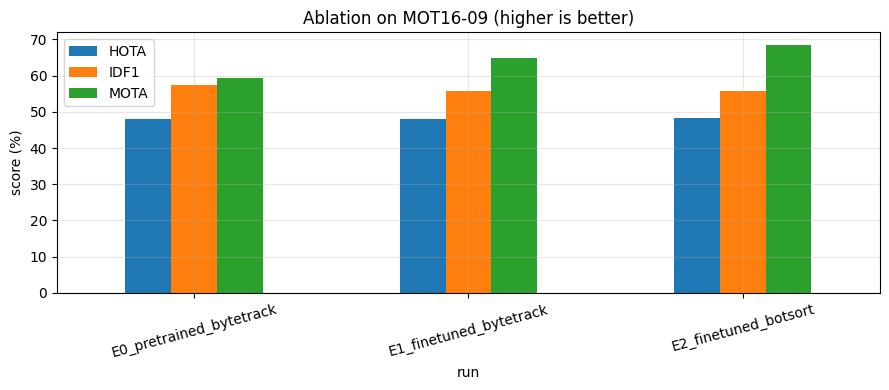

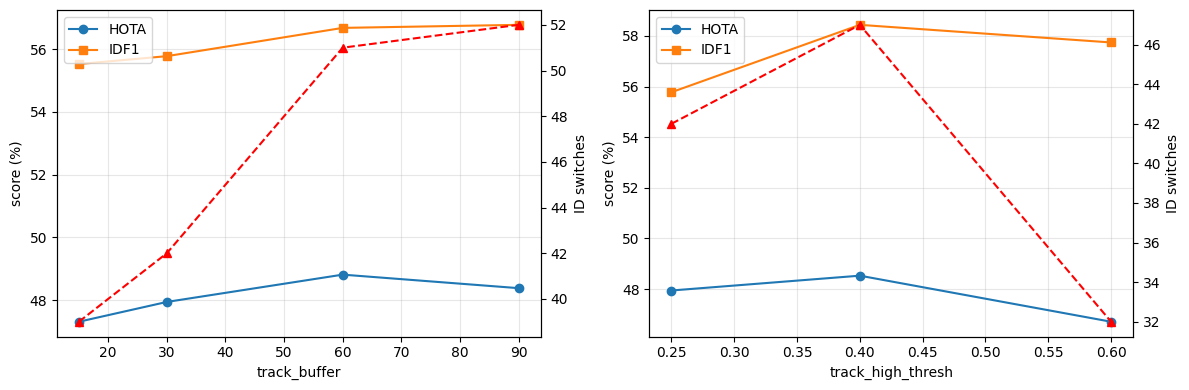

In [ ]:
# 10. Plots: ablation bars and sweep curves
import matplotlib.pyplot as plt
abl = table[table.index.str.startswith('E')]
ax = abl[['HOTA', 'IDF1', 'MOTA']].plot.bar(figsize=(9, 4), rot=15)
ax.set_title(f'Ablation on {SEQ} (higher is better)'); ax.set_ylabel('score (%)'); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(RESULTS/'tracking_ablation.png', dpi=130); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for a, (key, (param, values)) in zip(axes, SWEEPS.items()):
    sub = table.loc[[f'S_{key}_{v}' for v in values]]
    a.plot(values, sub['HOTA'].values, 'o-', label='HOTA'); a.plot(values, sub['IDF1'].values, 's-', label='IDF1')
    a2 = a.twinx(); a2.plot(values, sub['IDSW'].values, 'r^--', label='ID switches'); a2.set_ylabel('ID switches')
    a.set_xlabel(param); a.set_ylabel('score (%)'); a.legend(loc='upper left'); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(RESULTS/'tracking_sweeps.png', dpi=130); plt.show()

In [ ]:
# 11. Choose the best configuration by HOTA and pick a target pedestrian
best_run = table.loc[[n for n in table.index if n.startswith('E')]]['HOTA'].idxmax()
print('Best core configuration:', best_run)
tr = pd.read_csv(TE_TRACKERS/best_run/'data'/f'{SEQ}.txt', header=None,
                 names=['frame','id','x','y','w','h','conf','a','b','c'])
tracks = tr.groupby('id').frame.agg(first='min', last='max', n='count')
tracks['span'] = tracks['last'] - tracks['first'] + 1
tracks['gaps'] = tracks['span'] - tracks['n']        # frames missing inside the track's lifetime (occlusion / missed detection)
display(tracks.sort_values('n', ascending=False).head(8))

TARGET_ID = None      # set an ID from the table above, or leave None to use the longest track
if TARGET_ID is None:
    TARGET_ID = int(tracks['n'].idxmax())
print('Target ID:', TARGET_ID, '| frames:', int(tracks.loc[TARGET_ID, 'n']))

Best core configuration: E2_finetuned_botsort


,first,last,n,span,gaps
id,,,,,
7,5,476,463,472,9
1,1,525,442,525,83
104,200,525,280,326,46
47,136,392,245,257,12
3,1,230,220,230,10
92,188,443,213,256,43
69,167,381,208,215,7
76,172,373,199,202,3


Target ID: 7 | frames: 463


In [ ]:
# 12. Render videos: (a) all tracks, (b) single highlighted target with trail
import cv2, random
def color_for(i):
    r = random.Random(int(i)); return tuple(r.randrange(60, 255) for _ in range(3))

def render(df, out_path, target=None):
    first = cv2.imread(str(IMG_DIR/'000001.jpg')); H, W = first.shape[:2]
    vw = cv2.VideoWriter(str(out_path), cv2.VideoWriter_fourcc(*'mp4v'), FPS_VIDEO, (W, H))
    by_frame = {f: g for f, g in df.groupby('frame')}
    trail = []
    for f in range(1, N_FRAMES + 1):
        img = cv2.imread(str(IMG_DIR/f'{f:06d}.jpg'))
        for r in by_frame.get(f, pd.DataFrame()).itertuples():
            x, y, w, h = int(r.x), int(r.y), int(r.w), int(r.h)
            if target is None:
                c = color_for(r.id); cv2.rectangle(img, (x, y), (x+w, y+h), c, 2)
                cv2.putText(img, str(r.id), (x, max(y-4, 14)), cv2.FONT_HERSHEY_SIMPLEX, 0.7, c, 2)
            elif r.id == target:
                cv2.rectangle(img, (x, y), (x+w, y+h), (0, 255, 0), 4)
                cv2.putText(img, f'TARGET ID {r.id}', (x, max(y-8, 20)), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 255, 0), 3)
                trail.append((x + w//2, y + h))
            else:
                cv2.rectangle(img, (x, y), (x+w, y+h), (140, 140, 140), 1)     # dimmed context
        for p, q in zip(trail[-60:], trail[-59:]):
            cv2.line(img, p, q, (0, 255, 255), 3)
        vw.write(img)
    vw.release()

def to_h264(src):
    dst = src.with_name(src.stem + '_h264.mp4')
    subprocess.run(['ffmpeg', '-y', '-loglevel', 'error', '-i', str(src), '-vcodec', 'libx264', '-pix_fmt', 'yuv420p', str(dst)])
    return dst

render(tr, Path('/content/tracks_all.mp4'))
render(tr, Path('/content/tracks_target.mp4'), target=TARGET_ID)
for name in ['tracks_all', 'tracks_target']:
    dst = to_h264(Path(f'/content/{name}.mp4'))
    shutil.copy(dst, RESULTS/f'{SEQ}_{best_run}_{name}.mp4')
print('Videos saved to', RESULTS)

Videos saved to /content/drive/MyDrive/MOT16_project/Backup/results


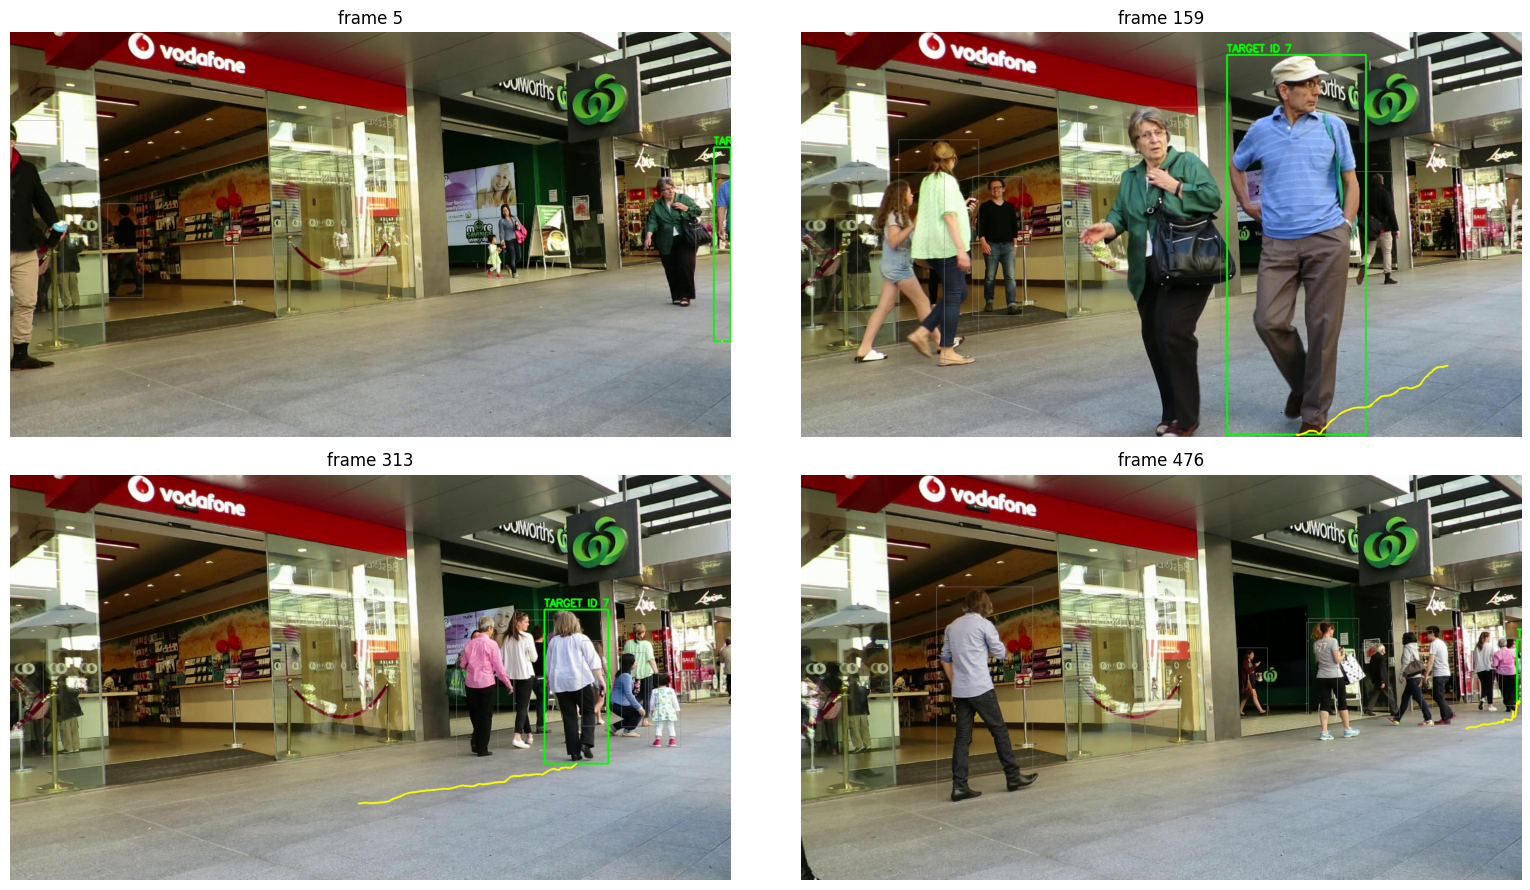

In [ ]:
# 13. Stills from the target video (download the MP4s from Drive for the presentation)
frames_with_target = sorted(tr[tr.id == TARGET_ID].frame.unique())
picks = [frames_with_target[i] for i in np.linspace(0, len(frames_with_target) - 1, 4, dtype=int)]
cap = cv2.VideoCapture('/content/tracks_target.mp4')
fig, axes = plt.subplots(2, 2, figsize=(16, 9))
for ax, f in zip(axes.ravel(), picks):
    cap.set(cv2.CAP_PROP_POS_FRAMES, f - 1); ok, img = cap.read()
    if ok: ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(f'frame {f}'); ax.axis('off')
plt.tight_layout(); plt.savefig(RESULTS/'target_stills.png', dpi=110); plt.show()

## Findings and Discussion

### 1. Video files: `tracks_target.mp4` and `tracks_target_h264.mp4`

The two files contain the same video. They differ only in the video codec.

- `tracks_target.mp4` was written by OpenCV with the `mp4v` codec. Many browsers and presentation programs cannot play this codec reliably.
- `tracks_target_h264.mp4` was converted with ffmpeg to the H.264 codec. Most players support H.264, so this file is used for the presentation and the submission.

### 2. Identity switch in the single-target video

In the target video, the same target ID appears on two different pedestrians. This is an **identity switch**. It is a tracking error and not a drawing error. The video shows only the boxes that the tracker labelled with the target ID, and the tracker never gives one ID to two boxes in the same frame. Therefore, the ID moved from one person to another person over time.

**Probable cause.** MOT16-09 contains moments when pedestrians cross paths or hide each other. In this experiment, ByteTrack and BoT-SORT use only box position and motion. They do not use a trained appearance model. When the target is hidden for a few frames, the predicted box of the target can land on another pedestrian. The tracker then matches this box with the wrong person. A missed detection at the same moment can cause the same error.

**Evidence.** The IDSW value in the evaluation table counts these switches. The frame where the target jumps to a new person can be seen in the stills from the last cell of Notebook 04.

### 3. Implications

- Position and motion cues are not enough in crowded scenes. This limit is the main motivation for the re-identification (ReID) model in Notebook 05.
- The longest track is not always the best target. A long track may have joined several people. For the final video, the target should be a track with few gaps and no visible switch.
- The ground-truth annotations are available for MOT16-09, so the quality of each track can be measured. For the MOT16 test sequences, no annotations are public, so the target must be checked visually.

### 4. Next steps

1. Record the frame number of the identity switch and use it as an example in the midterm presentation.
2. Select another target ID with fewer gaps, and render the video again.
3. Compare the number of identity switches with and without appearance features after Notebook 05.

Below is the text for a Markdown cell. I wrote it in the same tone as before. The causes are probable, not confirmed. The last section describes the check that will confirm them.


### 5. Missed pedestrians in the `tracks_all` video

Some pedestrians in the `tracks_all` video have no box and no ID. We measured these false negatives on MOT16-09 using 5,257 ground-truth pedestrians. The tracker E2 (fine-tuned detector with BoT-SORT) missed 1,139 of them (recall 0.783). Fine-tuning improved recall from 0.742 to 0.769, and BoT-SORT improved it to 0.783. Fine-tuning also reduced unmatched boxes from 1,753 to 669.

### 6. Causes supported by the evidence

1. **Heavy occlusion is the main cause.** Recall depends strongly on visibility: 0.43 (visibility 0–0.25), 0.76 (0.25–0.5), 0.90 (0.5–0.75), and 0.98 (0.75–1). The group with visibility below 0.25 contains 898 of the 1,139 missed boxes (79%).
2. **The track-start threshold removes some detections.** The detector alone reaches recall 0.810 at confidence 0.1, while the tracker output has 0.783. This difference (about 139 boxes) is close to the result of a detector at confidence 0.25 (0.780). Lowering the threshold increases recall, but it also increases unmatched boxes from 659 to 1,589.

### 7. Causes not supported by the evidence

- **Small or distant people.** All ground-truth pedestrians in MOT16-09 are at least 120 pixels tall.
- **Image size.** Increasing the inference size from 960 to 1280 pixels changed recall only from 0.810 to 0.815.
- **Crowded frames.** Recall was similar in sparse, medium, and crowded frames (0.79, 0.76, and 0.82).

### 8. Implications and possible improvements

- Better resolution will not solve most misses in this sequence. The detector needs to recognize partly hidden people.
- Options include training with more data that contains occlusion, a larger model, and lower thresholds with a check of the precision loss.
- Because the tracking is offline, missing frames inside a track could be filled by interpolation. This would raise recall for existing tracks, but it cannot recover people who were never detected.
- Appearance matching (Notebook 05) does not increase detection recall. It helps to connect the same person after occlusion, which should reduce identity switches.

### 9. Limitation

These results come from one sequence (MOT16-09), which has large pedestrians. Sequences with small pedestrians may show different causes.


## False-Negative Analysis (missed pedestrians)

**Question.** Some real pedestrians have no box and no ID in the video. Is the detector missing them, or does the tracker drop them? Which pedestrians are missed: small, hidden, or in crowds?

**Method.** For every frame, each ground-truth pedestrian is matched to at most one predicted box (IoU >= 0.5, Hungarian matching). Identities are ignored here, so this measures detection coverage only. A ground-truth box with no match is a *false negative* (missed pedestrian).

In [ ]:
# 14. Part 1 - How many ground-truth pedestrians does each run miss?
from scipy.optimize import linear_sum_assignment

gt_all   = pd.read_csv(SEQ_DIR/'gt'/'gt.txt', header=None, names=['frame','id','x','y','w','h','conf','cls','vis'])
gt_ped   = gt_all[(gt_all.cls == 1) & (gt_all.conf == 1)].reset_index(drop=True)   # what the benchmark evaluates
gt_other = gt_all[gt_all.cls != 1].reset_index(drop=True)                          # static persons, people on vehicles, reflections, distractors
print('GT rows per class (1=pedestrian, 2=person on vehicle, 7=static person, 8=distractor, 9=Occluder/Non-pedestrian human 12=reflection):')
print(gt_all.groupby('cls').size().to_dict())

def iou_xywh(a, b):
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    ax2, ay2 = a[:, 0] + a[:, 2], a[:, 1] + a[:, 3]
    bx2, by2 = b[:, 0] + b[:, 2], b[:, 1] + b[:, 3]
    iw = np.clip(np.minimum(ax2[:, None], bx2[None]) - np.maximum(a[:, 0][:, None], b[:, 0][None]), 0, None)
    ih = np.clip(np.minimum(ay2[:, None], by2[None]) - np.maximum(a[:, 1][:, None], b[:, 1][None]), 0, None)
    inter = iw * ih
    union = (a[:, 2] * a[:, 3])[:, None] + (b[:, 2] * b[:, 3])[None] - inter
    return inter / np.maximum(union, 1e-9)

G_BY_FRAME = gt_ped.groupby('frame').indices

def match_boxes(pred_by_frame, thr=0.5):
    # One-to-one matching per frame (Hungarian on IoU), IDs ignored.
    # Returns: hit (bool per GT pedestrian) and a table of unmatched predicted boxes.
    hit = np.zeros(len(gt_ped), dtype=bool); extra = []
    for f in range(1, N_FRAMES + 1):
        gi = G_BY_FRAME.get(f, np.array([], dtype=int))
        p = pred_by_frame.get(f, np.zeros((0, 4)))
        used = set()
        if len(gi) and len(p):
            iou = iou_xywh(gt_ped.loc[gi, ['x','y','w','h']].values, p)
            r, c = linear_sum_assignment(-iou)
            for i, j in zip(r, c):
                if iou[i, j] >= thr:
                    hit[gi[i]] = True; used.add(j)
        extra += [(f, *p[j]) for j in range(len(p)) if j not in used]
    return hit, pd.DataFrame(extra, columns=['frame','x','y','w','h'])

def load_pred(run):
    t = pd.read_csv(TE_TRACKERS/run/'data'/f'{SEQ}.txt', header=None,
                    names=['frame','id','x','y','w','h','conf','a','b','c'])
    return {f: g[['x','y','w','h']].values for f, g in t.groupby('frame')}

HITS, rows = {}, []
for run in sorted(p.name for p in TE_TRACKERS.iterdir() if p.is_dir() and p.name.startswith('E')):
    hit, extra = match_boxes(load_pred(run)); HITS[run] = (hit, extra)
    rows.append(dict(run=run, gt_boxes=len(hit), missed=int((~hit).sum()),
                     recall=round(float(hit.mean()), 3), unmatched_pred_boxes=len(extra)))
fn_table = pd.DataFrame(rows).set_index('run'); display(fn_table)
fn_table.to_csv(RESULTS/'fn_summary.csv')

GT rows per class (1=pedestrian, 2=person on vehicle, 7=static person, 8=distractor, 9=Occluder/Non-pedestrian human 12=reflection):
{1: 5257, 8: 1575, 9: 1050, 12: 948}


,gt_boxes,missed,recall,unmatched_pred_boxes
run,,,,
E0_pretrained_bytetrack,5257,1356,0.742,1753
E1_finetuned_bytetrack,5257,1216,0.769,669
E2_finetuned_botsort,5257,1139,0.783,659



By height_px:


,n,recall,missed
height_px,,,
120-200,810,0.602,322
>200,4447,0.816,817



By visibility:


,n,recall,missed
visibility,,,
0-0.25,1564,0.426,898
0.25-0.5,577,0.764,136
0.5-0.75,612,0.904,59
0.75-1,2504,0.982,46



By people_in_frame:


,n,recall,missed
people_in_frame,,,
"(5.999, 10.0]",2341,0.786,500
"(10.0, 12.0]",1889,0.759,456
"(12.0, 13.0]",1027,0.822,183


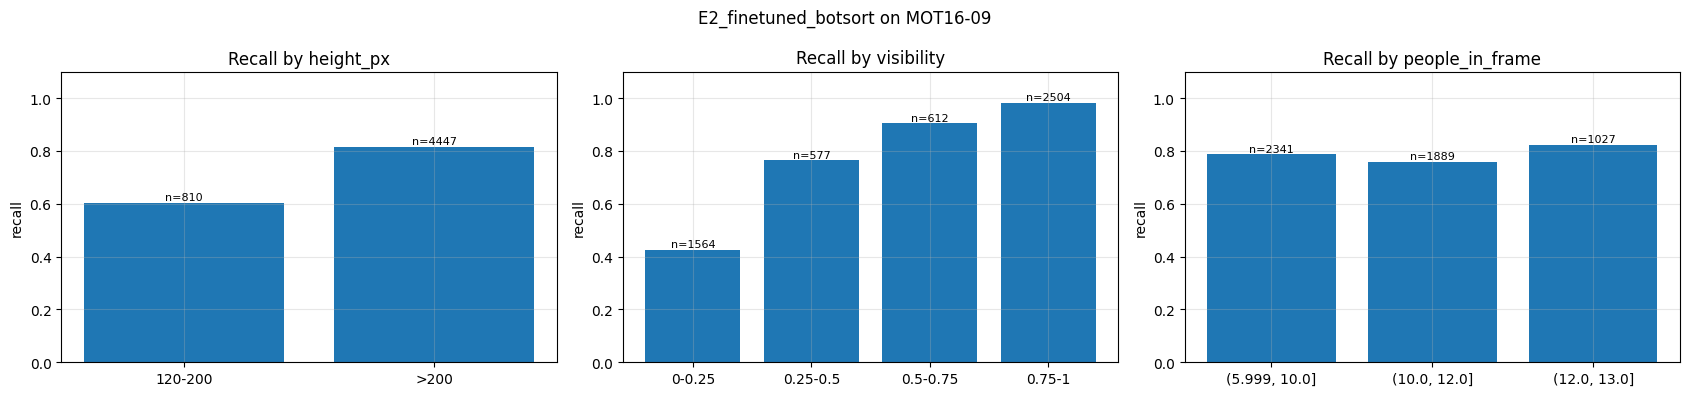

In [ ]:
# 15. Part 2 - WHICH pedestrians are missed? Recall by box height, visibility and crowd level (best run)
hit, extra = HITS[best_run]
g = gt_ped.assign(hit=hit)
g['height_px'] = pd.cut(g.h, [0, 50, 80, 120, 200, 5000], labels=['<50', '50-80', '80-120', '120-200', '>200'])
g['visibility'] = pd.cut(g.vis, [-0.01, 0.25, 0.5, 0.75, 1.0], labels=['0-0.25', '0.25-0.5', '0.5-0.75', '0.75-1'])
g['people_in_frame'] = pd.qcut(g.groupby('frame').frame.transform('size'), 3, duplicates='drop')

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, col in zip(axes, ['height_px', 'visibility', 'people_in_frame']):
    s = g.groupby(col, observed=True).hit.agg(n='size', recall='mean')
    s['missed'] = (s.n * (1 - s.recall)).round().astype(int)
    print(f'\nBy {col}:'); display(s.round(3))
    ax.bar(s.index.astype(str), s.recall, color='tab:blue')
    for i, (rc, n) in enumerate(zip(s.recall, s.n)):
        ax.text(i, rc + 0.01, f'n={n}', ha='center', fontsize=8)
    ax.set_ylim(0, 1.1); ax.set_title(f'Recall by {col}'); ax.set_ylabel('recall'); ax.grid(alpha=.3)
plt.suptitle(f'{best_run} on {SEQ}'); plt.tight_layout()
plt.savefig(RESULTS/'fn_breakdown.png', dpi=130); plt.show()

In [ ]:
# 16. Part 3 - Detector or tracker? Compare raw detector recall with the tracker output.
# If the raw detector finds the person but the tracker output does not, the loss is in the tracker (track-start rules).
# If the raw detector also misses the person, the cause is the detector (small size, resolution, training data).
det_model = YOLO(WEIGHTS_FT)
IMGSZ_LIST = [IMGSZ, 1280]            # also test a larger inference size
rows = [dict(source=f'tracker output ({best_run})', recall=round(float(HITS[best_run][0].mean()), 3),
             missed=int((~HITS[best_run][0]).sum()), unmatched_pred_boxes=len(HITS[best_run][1]))]
RAW = {}
for sz in IMGSZ_LIST:
    raw = {}
    for r in det_model.predict(source=str(IMG_DIR), stream=True, conf=DET_CONF, imgsz=sz, verbose=False):
        f = int(Path(r.path).stem); xy = r.boxes.xyxy.cpu().numpy(); sc = r.boxes.conf.cpu().numpy()
        raw[f] = (np.c_[xy[:, 0], xy[:, 1], xy[:, 2] - xy[:, 0], xy[:, 3] - xy[:, 1]], sc)
    RAW[sz] = raw
    for th in [0.1, 0.25, 0.5]:
        h, e = match_boxes({f: b[s >= th] for f, (b, s) in raw.items()})
        rows.append(dict(source=f'detector, imgsz={sz}, conf>={th}', recall=round(float(h.mean()), 3),
                         missed=int((~h).sum()), unmatched_pred_boxes=len(e)))
cmp_table = pd.DataFrame(rows).set_index('source'); display(cmp_table)
cmp_table.to_csv(RESULTS/'fn_detector_vs_tracker.csv')

,recall,missed,unmatched_pred_boxes
source,,,
tracker output (E2_finetuned_botsort),0.783,1139,659
"detector, imgsz=960, conf>=0.1",0.810,1000,1589
"detector, imgsz=960, conf>=0.25",0.780,1157,794
"detector, imgsz=960, conf>=0.5",0.732,1411,391
"detector, imgsz=1280, conf>=0.1",0.815,971,1934
"detector, imgsz=1280, conf>=0.25",0.789,1111,975
"detector, imgsz=1280, conf>=0.5",0.747,1332,461


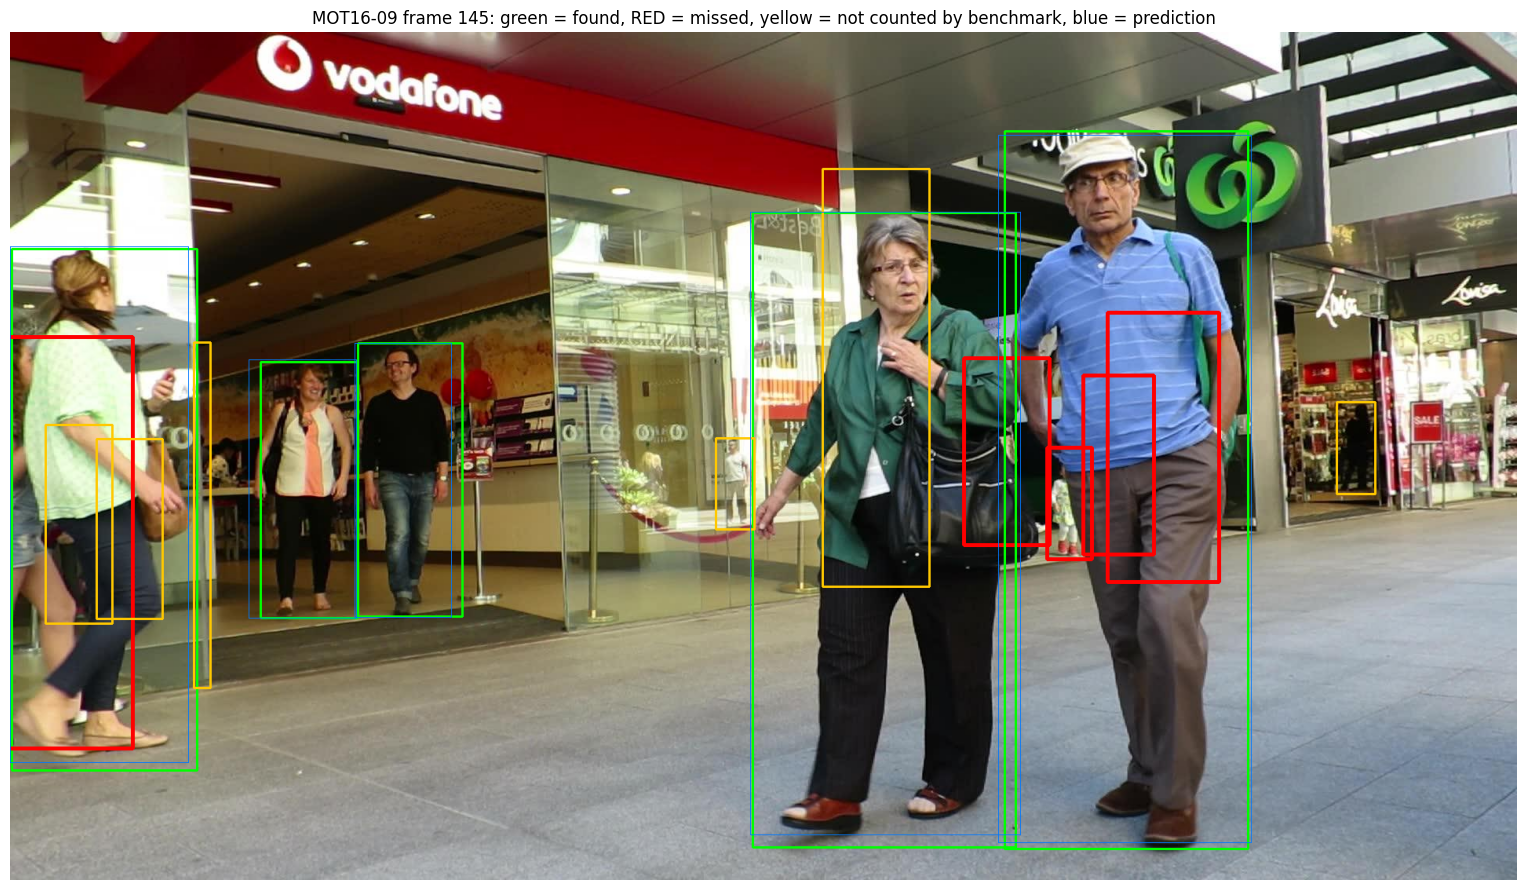

Unmatched predicted boxes: 659 | on non-evaluated people (class != 1): 204


In [ ]:
# 17. Part 4 - Look at the worst frame, and check whether "extra" boxes are real people that the benchmark does not count
hit, extra = HITS[best_run]
g = gt_ped.assign(hit=hit)
worst = int(g[~g.hit].groupby('frame').size().idxmax())
img = cv2.cvtColor(cv2.imread(str(IMG_DIR/f'{worst:06d}.jpg')), cv2.COLOR_BGR2RGB)
for r in g[g.frame == worst].itertuples():
    x, y, w, h = map(int, (r.x, r.y, r.w, r.h))
    cv2.rectangle(img, (x, y), (x + w, y + h), (0, 255, 0) if r.hit else (255, 0, 0), 2 if r.hit else 4)   # green = found, red = missed
for r in gt_other[gt_other.frame == worst].itertuples():
    x, y, w, h = map(int, (r.x, r.y, r.w, r.h))
    cv2.rectangle(img, (x, y), (x + w, y + h), (255, 200, 0), 2)                                        # yellow = person the benchmark does not count
for (x, y, w, h) in load_pred(best_run).get(worst, np.zeros((0, 4))).astype(int):
    cv2.rectangle(img, (x, y), (x + w, y + h), (0, 120, 255), 1)                                        # blue = predicted box
plt.figure(figsize=(16, 9)); plt.imshow(img); plt.axis('off')
plt.title(f'{SEQ} frame {worst}: green = found, RED = missed, yellow = not counted by benchmark, blue = prediction')
plt.tight_layout(); plt.savefig(RESULTS/'fn_worst_frame.png', dpi=130); plt.show()

# Unmatched predicted boxes that sit on a non-evaluated person (class != 1) are not real errors
o_by = gt_other.groupby('frame').indices; explained = 0
for f, grp in extra.groupby('frame'):
    oi = o_by.get(f)
    if oi is None: continue
    iou = iou_xywh(grp[['x','y','w','h']].values, gt_other.iloc[oi][['x','y','w','h']].values)
    explained += int((iou.max(axis=1) >= 0.5).sum())
print(f'Unmatched predicted boxes: {len(extra)} | on non-evaluated people (class != 1): {explained}')

### How to read the results
- **Part 1.** Recall is the share of ground-truth pedestrians that received a box. `missed` is the number of false negatives.
- **Part 2.** If recall falls for small boxes (height < 50-80 px), the main cause is distance and image size. If it falls for low visibility, the cause is occlusion. If it falls in crowded frames, the cause may be overlap and non-maximum suppression.
- **Part 3.** Compare *tracker output* with *detector, conf >= 0.1*:
  - Detector recall is much higher than tracker recall: the tracker loses people (track-start threshold, start delay). Try lower `new_track_thresh` and `track_high_thresh`.
  - Both are low: the detector is the limit. Try a larger image size, more training data or epochs.
  - Recall improves at imgsz 1280: small pedestrians are the cause. Consider training at 1280.
- **Part 4.** Red boxes show the missed people. Yellow boxes are people the benchmark does not count. Predictions on them are not true errors.

The results change my earlier explanation. Some of the causes I listed as probable are not supported by your data, so I'll say which ones before the revised findings text.

## What the data shows

| Earlier hypothesis | Result | Evidence |
|---|---|---|
| Small and distant people | **Not supported** | No ground-truth pedestrian in MOT16-09 is shorter than 120 px. The bins below 120 px are empty. |
| Image size too small | **Mostly not supported** | Going from 960 to 1280 raises recall only from 0.810 to 0.815, which is 29 fewer misses. |
| Strict new-track threshold | **Partly supported** | Tracker recall is 0.783, and detector recall at conf ≥ 0.1 is 0.810. About 139 boxes, or 2.7 points, are lost in the tracker. |
| Heavy occlusion | **Supported, and it is the main cause** | Of the 1,139 misses, 898 (79%) are boxes with visibility below 0.25. Recall rises steadily with visibility: 0.43, 0.76, 0.90, 0.98. |
| Crowded frames | **Not supported** | Recall is similar across crowd levels: 0.79, 0.76, 0.82. |
| Non-evaluated people | **Not yet tested** | It needs the cell 17 output. Those classes (8, 9, 12) have no ground-truth boxes to miss, but they could explain "real people with no ID" in the video. |

Other points from the three outputs:
- **Fine-tuning helped, mostly by reducing false boxes.** Unmatched boxes fell from 1,753 to 669 (−62%), and recall rose from 0.742 to 0.769. BoT-SORT adds another 0.014, reaching 0.783.
- **The tracker output matches a 0.25-confidence detector.** Detector recall at conf ≥ 0.25 and 960 is 0.780, close to the tracker's 0.783. This fits the 0.25 track-start threshold.
- **Lowering the threshold costs precision.** At conf ≥ 0.1 the detector has 1,589 unmatched boxes, against 659 for the tracker.
- **The detector alone still misses about 19%.** That is roughly 1,000 boxes, mostly heavily hidden people. Resolution and thresholds will not fix those.